# Comprensión de datos y EDA — Avance 1

Análisis exploratorio de préstamos y pago a tiempo. Se parte siempre del CSV original; las modificaciones de este notebook son experimentales y **no se exporta un dataset transformado**.

## 1. Librerías y carga

In [2]:
##from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from cargar_datos_avance1 import cargarDatos

sns.set_theme(style="whitegrid", palette="viridis")

# Load the original dataset from CSV
df_original = cargarDatos()

# Convert the date column to datetime
df_original["fecha_prestamo"] = pd.to_datetime(
    df_original["fecha_prestamo"]
)

# Create a copy for exploratory analysis
df = df_original.copy()

# Display dataset dimensions and first rows
print(f"Filas: {df.shape[0]:,} | Columnas: {df.shape[1]}")
display(df.head())

Filas: 10,763 | Columnas: 23


,tipo_credito,fecha_prestamo,capital_prestado,plazo_meses,edad_cliente,tipo_laboral,salario_cliente,total_otros_prestamos,cuota_pactada,puntaje,...,saldo_mora,saldo_total,saldo_principal,saldo_mora_codeudor,creditos_sectorFinanciero,creditos_sectorCooperativo,creditos_sectorReal,promedio_ingresos_datacredito,tendencia_ingresos,Pago_atiempo
0,7,2024-12-21 11:31:35,3692160.0,10,42,Independiente,8000000,2500000,341296,88.768094,...,0.0,51258.0,51258.0,0.0,5,0,0,908526.0,Estable,1
1,4,2025-04-22 09:47:35,840000.0,6,60,Empleado,3000000,2000000,124876,95.227787,...,0.0,8673.0,8673.0,0.0,0,0,2,939017.0,Creciente,1
2,9,2026-01-08 12:22:40,5974028.4,10,36,Independiente,4036000,829000,529554,47.613894,...,0.0,18702.0,18702.0,0.0,3,0,0,NaN,NaN,0
3,4,2025-08-04 12:04:10,1671240.0,6,48,Empleado,1524547,498000,252420,95.227787,...,0.0,15782.0,15782.0,0.0,3,0,0,1536193.0,Creciente,1
4,9,2025-04-26 11:24:26,2781636.0,11,44,Empleado,5000000,4000000,217037,95.227787,...,0.0,204804.0,204804.0,0.0,3,0,1,933473.0,Creciente,1


## 2. Estructura y calidad de datos

Se revisan tipos, faltantes, duplicados y categorías antes de decidir cambios.

In [3]:
df.info()
display(df.describe(include="all").T)
calidad = pd.DataFrame({"nulos": df.isna().sum(), "porcentaje_nulos": df.isna().mean().mul(100).round(2), "tipo": df.dtypes.astype(str)})
display(calidad.sort_values("porcentaje_nulos", ascending=False))
print("Filas duplicadas:", df.duplicated().sum())
for columna in ["tipo_credito", "tipo_laboral", "tendencia_ingresos", "Pago_atiempo"]:
    print(f"\n{columna}")
    print(df[columna].value_counts(dropna=False).head(20))

<class 'pandas.DataFrame'>
RangeIndex: 10763 entries, 0 to 10762
Data columns (total 23 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   tipo_credito                   10763 non-null  int64         
 1   fecha_prestamo                 10763 non-null  datetime64[us]
 2   capital_prestado               10763 non-null  float64       
 3   plazo_meses                    10763 non-null  int64         
 4   edad_cliente                   10763 non-null  int64         
 5   tipo_laboral                   10763 non-null  str           
 6   salario_cliente                10763 non-null  int64         
 7   total_otros_prestamos          10763 non-null  int64         
 8   cuota_pactada                  10763 non-null  int64         
 9   puntaje                        10763 non-null  float64       
 10  puntaje_datacredito            10757 non-null  float64       
 11  cant_creditosvigentes     

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
tipo_credito,10763.0,NaN,NaN,NaN,5.411131,4.0,4.0,4.0,9.0,68.0,2.338279
fecha_prestamo,10763,NaN,NaN,NaN,2025-04-16 23:06:02.111121,2024-11-26 09:17:04,2025-01-20 17:33:07.500000,2025-03-27 16:23:12,2025-06-16 13:27:58,2026-04-26 18:43:52,NaN
capital_prestado,10763.0,NaN,NaN,NaN,2434315.001319,360000.0,1224831.0,1921920.0,3084840.0,41444152.8,1909642.758997
plazo_meses,10763.0,NaN,NaN,NaN,10.575583,2.0,6.0,10.0,12.0,90.0,6.632082
edad_cliente,10763.0,NaN,NaN,NaN,43.94862,19.0,33.0,42.0,53.0,123.0,15.060877
tipo_laboral,10763,2,Empleado,6754,NaN,NaN,NaN,NaN,NaN,NaN,NaN
salario_cliente,10763.0,NaN,NaN,NaN,17216431.459909,0.0,2000000.0,3000000.0,4875808.0,22000000000.0,355476717.603482
total_otros_prestamos,10763.0,NaN,NaN,NaN,6238869.648518,0.0,500000.0,1000000.0,2000000.0,6787675263.0,118418316.941069
cuota_pactada,10763.0,NaN,NaN,NaN,243617.406671,23944.0,121041.5,182863.0,287833.5,3816752.0,210493.694608
puntaje,10763.0,NaN,NaN,NaN,91.170036,-38.00999,95.227787,95.227787,95.227787,95.227787,16.465441


,nulos,porcentaje_nulos,tipo
tendencia_ingresos,2932,27.24,str
promedio_ingresos_datacredito,2930,27.22,float64
saldo_mora_codeudor,590,5.48,float64
saldo_principal,405,3.76,float64
saldo_total,156,1.45,float64
saldo_mora,156,1.45,float64
puntaje_datacredito,6,0.06,float64
tipo_credito,0,0.00,int64
huella_consulta,0,0.00,int64
creditos_sectorReal,0,0.00,int64


Filas duplicadas: 0

tipo_credito
tipo_credito
4     7747
9     2876
10     116
6       21
7        2
68       1
Name: count, dtype: int64

tipo_laboral
tipo_laboral
Empleado         6754
Independiente    4009
Name: count, dtype: int64

tendencia_ingresos
tendencia_ingresos
Creciente      5294
NaN            2932
Decreciente    1291
Estable        1188
0                 7
8315              6
1000000           4
9147              2
158042            1
3978              1
168750            1
-28589            1
-566272           1
24702             1
31837             1
122727            1
417087            1
9090              1
173031            1
-70715            1
Name: count, dtype: int64

Pago_atiempo
Pago_atiempo
1    10252
0      511
Name: count, dtype: int64


## 3. Limpieza exploratoria

Unificamos marcadores de ausencia. Los valores inesperados de `tendencia_ingresos` se tratan como faltantes, sin descartar filas. Se conserva la información de plazo y fecha para evaluar su utilidad más adelante. No imputamos indiscriminadamente: un nulo en información crediticia podría significar falta de registro y no un valor cero.

In [4]:
df = df.replace(["NA", "N/A", "null", "NULL", "?", "Sin dato", ""], np.nan)
validas = ["Creciente", "Decreciente", "Estable"]
invalidas = df["tendencia_ingresos"].notna() & ~df["tendencia_ingresos"].isin(validas)
print("Tendencias inválidas convertidas a NA:", invalidas.sum())
df.loc[invalidas, "tendencia_ingresos"] = np.nan
for columna in ["tipo_credito", "tipo_laboral", "tendencia_ingresos"]:
    df[columna] = df[columna].astype("category")
# Ejemplo de imputación SOLO para explorar: no sustituir datos originales ni aplicar al target.
df["tendencia_ingresos_eda"] = df["tendencia_ingresos"].cat.add_categories(["No informado"]).fillna("No informado")
print("Nulos tras normalización de marcadores:")
display(df.isna().sum().loc[lambda s: s.gt(0)].sort_values(ascending=False))

Tendencias inválidas convertidas a NA: 58
Nulos tras normalización de marcadores:


tendencia_ingresos               2990
promedio_ingresos_datacredito    2930
saldo_mora_codeudor               590
saldo_principal                   405
saldo_mora                        156
saldo_total                       156
puntaje_datacredito                 6
dtype: int64

## 4. Análisis univariable

Seleccionamos pocas variables representativas: monto, salario y puntaje. El boxplot del capital ayuda a visualizar valores extremos; no implica eliminarlos.

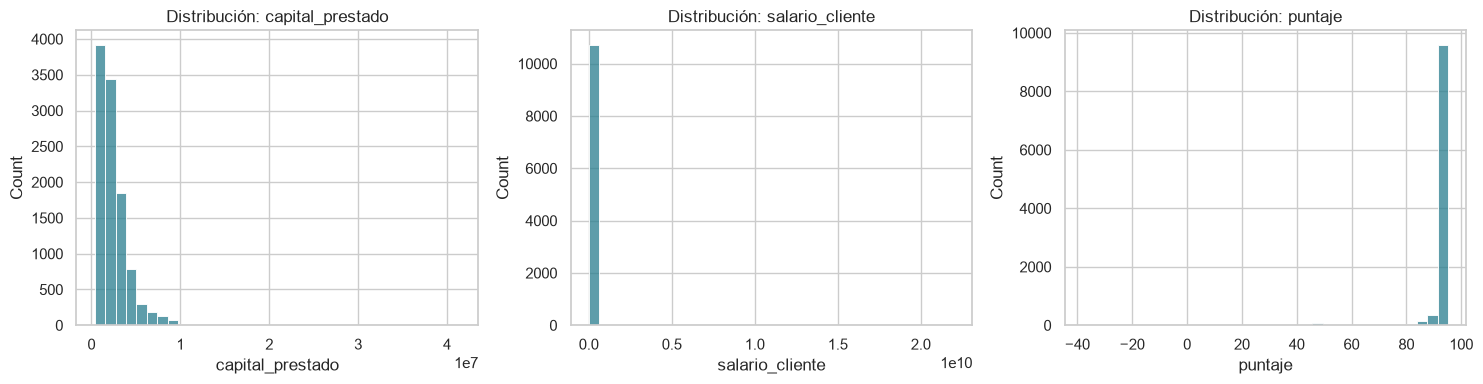

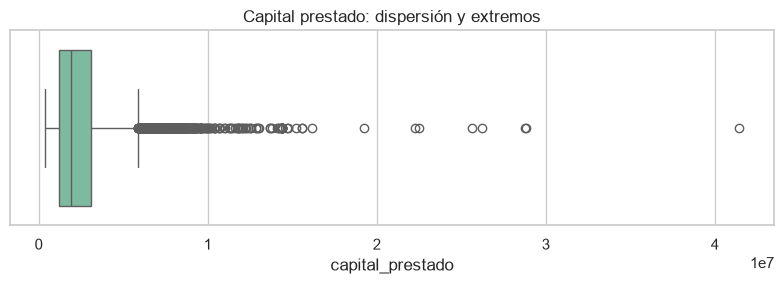

,count,mean,std,min,25%,50%,75%,max
capital_prestado,10763.0,2.434315e+06,1.909643e+06,360000.00000,1.224831e+06,1.921920e+06,3.084840e+06,4.144415e+07
salario_cliente,10763.0,1.721643e+07,3.554767e+08,0.00000,2.000000e+06,3.000000e+06,4.875808e+06,2.200000e+10
puntaje,10763.0,9.117004e+01,1.646544e+01,-38.00999,9.522779e+01,9.522779e+01,9.522779e+01,9.522779e+01
edad_cliente,10763.0,4.394862e+01,1.506088e+01,19.00000,3.300000e+01,4.200000e+01,5.300000e+01,1.230000e+02


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, columna in zip(axes, ["capital_prestado", "salario_cliente", "puntaje"]):
    sns.histplot(data=df, x=columna, bins=35, ax=ax, color="#287D8E")
    ax.set_title(f"Distribución: {columna}")
plt.tight_layout(); plt.show()
plt.figure(figsize=(8, 3))
sns.boxplot(data=df, x="capital_prestado", color="#73C5A2")
plt.title("Capital prestado: dispersión y extremos")
plt.tight_layout(); plt.show()
display(df[["capital_prestado", "salario_cliente", "puntaje", "edad_cliente"]].describe().T)

## 5. Variable objetivo y análisis bivariado

`Pago_atiempo` está codificada como 1 (pago a tiempo) y 0 (no pago a tiempo). Comparamos las tasas por tipo de crédito y la distribución del puntaje por resultado. Las categorías con muy pocos casos requieren cautela.

Distribución de la variable objetivo:


Pago_atiempo
1    95.25
0     4.75
Name: porcentaje, dtype: float64

,casos,tasa_pago
tipo_credito,,
4,7747,95.31
6,21,57.14
7,2,100.00
9,2876,95.27
10,116,97.41
68,1,100.00


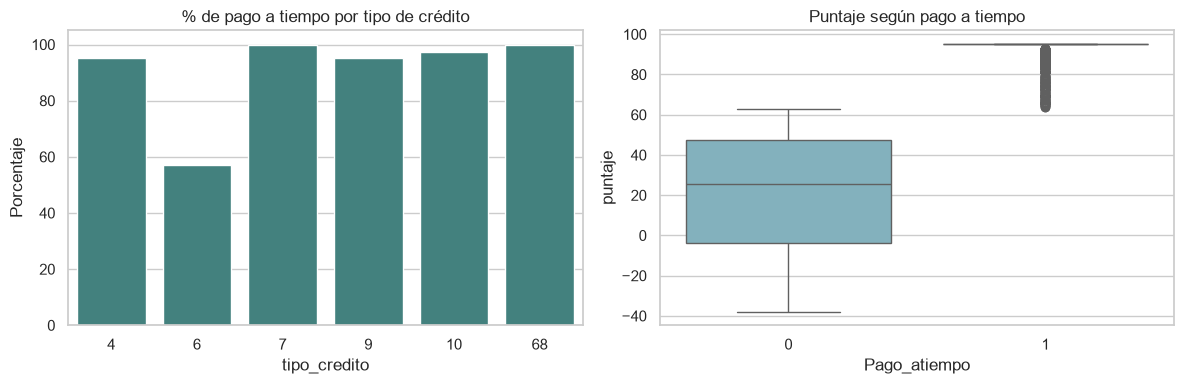

In [6]:
print("Distribución de la variable objetivo:")
display(df["Pago_atiempo"].value_counts(normalize=True).mul(100).round(2).rename("porcentaje"))
resumen_credito = df.groupby("tipo_credito", observed=True)["Pago_atiempo"].agg(casos="size", tasa_pago="mean")
resumen_credito["tasa_pago"] = resumen_credito["tasa_pago"].mul(100).round(2)
display(resumen_credito)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=resumen_credito.reset_index(), x="tipo_credito", y="tasa_pago", color="#398B87", ax=axes[0])
axes[0].set_title("% de pago a tiempo por tipo de crédito"); axes[0].set_ylabel("Porcentaje")
sns.boxplot(data=df, x="Pago_atiempo", y="puntaje", color="#79B7C7", ax=axes[1])
axes[1].set_title("Puntaje según pago a tiempo")
plt.tight_layout(); plt.show()

## 6. Relaciones multivariables

La matriz de correlación resume relaciones lineales entre variables numéricas. Una correlación alta no demuestra causalidad; además, los indicadores de mora podrían no estar disponibles en el momento de la predicción.

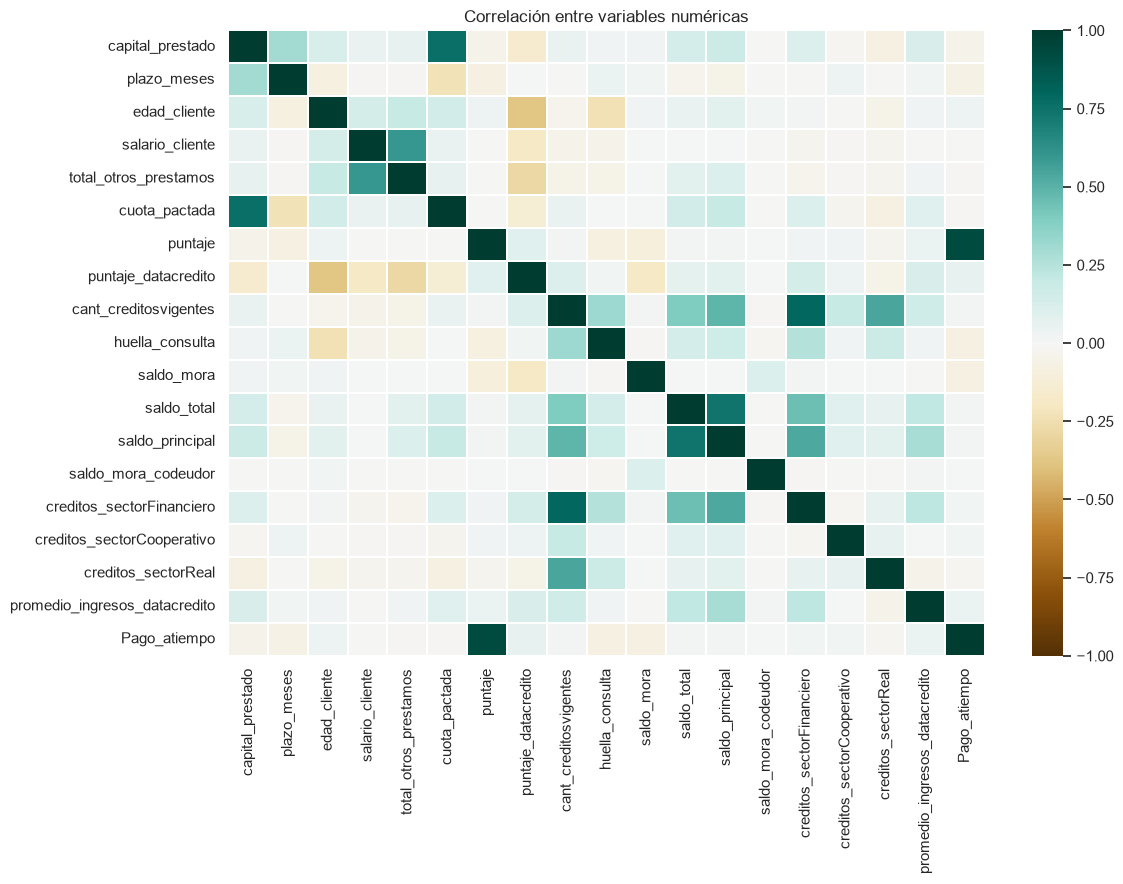

Correlación con Pago_atiempo (ordenada por magnitud):


puntaje                          0.923
huella_consulta                 -0.074
saldo_mora                      -0.073
puntaje_datacredito              0.068
plazo_meses                     -0.063
capital_prestado                -0.041
promedio_ingresos_datacredito    0.040
edad_cliente                     0.032
creditos_sectorReal             -0.023
creditos_sectorFinanciero        0.021
creditos_sectorCooperativo       0.021
saldo_total                      0.014
cuota_pactada                   -0.012
saldo_principal                  0.011
total_otros_prestamos           -0.010
cant_creditosvigentes            0.009
salario_cliente                 -0.004
saldo_mora_codeudor              0.003
Name: Pago_atiempo, dtype: float64

In [7]:
numericas = df.select_dtypes(include="number")
corr = numericas.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, cmap="BrBG", center=0, vmin=-1, vmax=1, linewidths=.2)
plt.title("Correlación entre variables numéricas")
plt.tight_layout(); plt.show()
print("Correlación con Pago_atiempo (ordenada por magnitud):")
display(corr["Pago_atiempo"].drop("Pago_atiempo").dropna().reindex(corr["Pago_atiempo"].drop("Pago_atiempo").dropna().abs().sort_values(ascending=False).index).round(3))

## 7. Hallazgos y reglas para la próxima etapa

- Verificar el porcentaje de faltantes por columna antes de elegir una estrategia de imputación. No convertir automáticamente todos los saldos faltantes en cero.
- Validar dominios: `Pago_atiempo` en {0, 1}, `tendencia_ingresos` en {Creciente, Decreciente, Estable} o faltante, y montos/plazos dentro de rangos plausibles.
- Considerar el desbalance de la variable objetivo al evaluar modelos (por ejemplo, recall y precision para la clase minoritaria).
- Revisar si `saldo_mora`, `puntaje` u otras variables se conocen **antes** del resultado de pago; de lo contrario podría existir fuga de información (*data leakage*).
- Analizar el tratamiento de categorías poco frecuentes sin eliminarlas automáticamente.
- Evaluar imputación, codificación y escalado en `ft_engineering` con ajustes aprendidos solo del conjunto de entrenamiento.

**Conclusión:** este notebook explora y documenta decisiones; el siguiente avance deberá volver a cargar el CSV original y reproducir las transformaciones seleccionadas dentro del flujo de entrenamiento.